In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
df = pd.read_csv(r"C:\Users\HP\Downloads\california_housing.csv")

In [39]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [40]:
X = df[["MedInc"]]
y = df["MedHouseVal"]

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


Polynomial Degree: 1
Training MSE: 0.6991447170182823
Testing MSE: 0.7091157771765549
Testing R2 Score: 0.45885918903846656

Polynomial Degree: 2
Training MSE: 0.6929887977115865
Testing MSE: 0.7032732680932143
Testing R2 Score: 0.46331772769346236

Polynomial Degree: 3
Training MSE: 0.6806795207431472
Testing MSE: 0.6982964744960335
Testing R2 Score: 0.4671156210838615

Polynomial Degree: 4
Training MSE: 0.6805417816982363
Testing MSE: 0.6981042443894434
Testing R2 Score: 0.46726231582556577


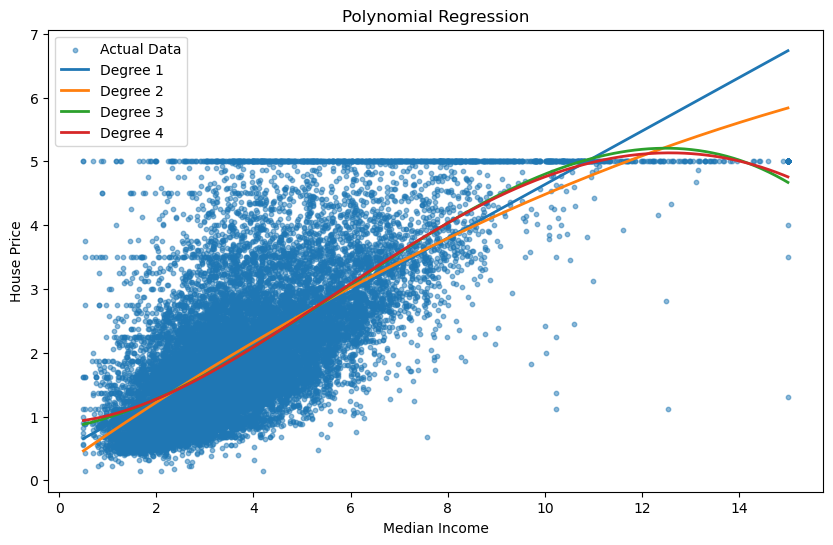

In [44]:
plt.figure(figsize=(10, 6))
plt.scatter(X["MedInc"], y, label="Actual Data", alpha=0.5, s=10)

x_plot = pd.DataFrame({"MedInc": np.linspace(X["MedInc"].min(), X["MedInc"].max(), 300)})

for degree in [1, 2, 3, 4]:

    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    train_pred = model.predict(X_train_poly)
    test_pred = model.predict(X_test_poly)

    print("\nPolynomial Degree:", degree)
    print("Training MSE:", mean_squared_error(y_train, train_pred))
    print("Testing MSE:", mean_squared_error(y_test, test_pred))
    print("Testing R2 Score:", r2_score(y_test, test_pred))

    x_poly = poly.transform(x_plot)
    y_plot = model.predict(x_poly)

    plt.plot(x_plot, y_plot, label=f"Degree {degree}", linewidth=2)

plt.title("Polynomial Regression")
plt.xlabel("Median Income")
plt.ylabel("House Price")
plt.legend()
plt.show()